# 01 · Comprensión del dominio y *Data Profiling*

**Práctica 2 — EDA y preparación de datasets** · Rol B (Dominio y Profiling) · Responsable: Jesús

Este notebook cubre las **secciones 1 y 2** de la práctica para los dos datasets del equipo, Titanic y Credit Card Fraud:

1. **Comprensión del dominio:** fuente, licencia, dimensiones, diccionario de variables y las preguntas sobre la variable objetivo, las fugas de información y los sesgos.
2. **Data profiling:** tipos, nulos, valores únicos, valores inválidos, estadísticas descriptivas, percentiles, asimetría, moda y frecuencias, duplicados, columnas casi constantes, categorías inconsistentes, identificadores, correlaciones altas y posibles fugas.

Cada dataset termina con una tabla de **hallazgos principales** (producto parcial). La sección 3 resume lo que se entrega a **Rol D** (qué imputar y winsorizar), a **Rol C** (qué conviene graficar) y a Rol A y Rol E.

| Sección | Contenido |
|---|---|
| 0 | Configuración y funciones de profiling (las mismas para ambos datasets) |
| 1 | Titanic: dominio, profiling y hallazgos |
| 2 | Credit Card Fraud: dominio, profiling y hallazgos |
| 3 | Entregas para los demás roles |
| 4 | Exportar tablas a `resultados/` |

> **Alcance.** El profiling usa los datos **crudos completos** porque es descriptivo: no ajusta ninguna transformación. Los límites IQR y percentiles que aparecen aquí son orientativos; Rol D debe recalcularlos **solo con train** (regla de oro del equipo).

**Datos necesarios:** `data/raw/titanic.csv` y `data/raw/creditcard.csv`. El segundo no está en el repositorio porque pesa ≈ 144 MB (ver README).

**Uso de IA generativa:** este notebook se elaboró con apoyo de Claude (Anthropic) para estructurar las funciones de profiling y redactar el borrador de las interpretaciones. Todas las cifras salen de ejecutar este notebook sobre los datos crudos.

## 0. Configuración

In [1]:
import sys
sys.path.append("..")  # permite importar src/ desde la carpeta notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import chi2_contingency
from sklearn.metrics import roc_auc_score

from src.utils import RAIZ, RESULTADOS_DIR, cargar_datos, dividir

FIGURAS_DIR = RAIZ / "figuras"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)

# Estilo sobrio para las dos figuras de este notebook
SUPERFICIE, TINTA, TINTA_2 = "#fcfcfb", "#0b0b0b", "#52514e"
AZUL, NARANJA = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "text.color": TINTA, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
})

### Funciones de profiling

Se definen una sola vez y se aplican igual a los dos datasets, para que el procedimiento sea reproducible y comparable.

In [2]:
PERCENTILES = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]


def resumen_columnas(df):
    """Para TODAS las columnas: tipo, nulos, % de nulos, valores únicos y peso del valor más frecuente."""
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "%_nulos": df.isna().mean() * 100,
        "unicos": df.nunique(),
        "%_unicos": df.nunique() / df.notna().sum() * 100,   # respecto a los valores no nulos
        "%_valor_mas_frecuente": df.apply(
            lambda s: s.value_counts(normalize=True, dropna=False).iloc[0] * 100),
    })


def nivel_asimetria(skew):
    """Regla práctica: |skew| <= 0.5 baja, entre 0.5 y 1 moderada, > 1 alta."""
    if abs(skew) > 1:
        return "alta"
    return "moderada" if abs(skew) > 0.5 else "baja"


def limites_iqr(serie):
    """Límites de Tukey: Q1 − 1.5·IQR y Q3 + 1.5·IQR."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


def perfil_numericas(df, columnas):
    """Mín., máx., media, mediana, desviación, percentiles, asimetría, curtosis y outliers (regla IQR)."""
    filas = {}
    for c in columnas:
        s = df[c].dropna()
        lim_inf, lim_sup = limites_iqr(s)
        fuera = (s < lim_inf) | (s > lim_sup)
        fila = {"min": s.min(), "max": s.max(), "media": s.mean(),
                "mediana": s.median(), "desv_est": s.std()}
        for p in PERCENTILES:
            fila[f"p{round(p * 100)}"] = s.quantile(p)
        fila.update({"asimetria": s.skew(), "nivel_asimetria": nivel_asimetria(s.skew()),
                     "curtosis": s.kurt(), "lim_inf_IQR": lim_inf, "lim_sup_IQR": lim_sup,
                     "n_outliers_IQR": int(fuera.sum()), "%_outliers_IQR": fuera.mean() * 100})
        filas[c] = fila
    return pd.DataFrame.from_dict(filas, orient="index")


def perfil_categoricas(df, columnas):
    """Moda, frecuencia de la moda, número de categorías y categorías raras (< 1 % de los no nulos)."""
    filas = {}
    for c in columnas:
        frec = df[c].value_counts()                      # no cuenta los nulos
        raras = frec[frec / frec.sum() < 0.01]
        filas[c] = {"n_categorias": frec.size, "moda": frec.index[0], "frec_moda": frec.iloc[0],
                    "%_moda": frec.iloc[0] / frec.sum() * 100,
                    "n_categorias_raras": raras.size, "ejemplos_raras": list(raras.index[:5])}
    return pd.DataFrame.from_dict(filas, orient="index")


def frecuencias(serie):
    """Frecuencia absoluta y relativa; los nulos aparecen como una categoría más."""
    frec = serie.value_counts(dropna=False)
    return pd.DataFrame({"n": frec, "%": frec / len(serie) * 100})


def revisar_dominio(df, reglas):
    """Cuenta valores fuera del dominio válido. reglas = {nombre: (columna, función que marca inválidos)}."""
    filas = []
    for nombre, (col, es_invalido) in reglas.items():
        marca = es_invalido(df[col]) & df[col].notna()   # los nulos se reportan aparte
        filas.append({"regla": nombre, "columna": col, "n": int(marca.sum()),
                      "%": marca.mean() * 100, "ejemplos": list(df.loc[marca, col].unique()[:5])})
    return pd.DataFrame(filas).set_index("regla")


def columnas_casi_constantes(df, umbral=0.95):
    """Columnas en las que un solo valor (incluido NaN) ocupa más del `umbral` de las filas."""
    peso = df.apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0])
    return peso[peso > umbral]


def posibles_identificadores(df, umbral=0.5):
    """Columnas enteras o de texto con muchos valores distintos (>= umbral). Las float continuas se omiten."""
    filas = {}
    for c in df.columns:
        if pd.api.types.is_float_dtype(df[c]):
            continue
        pct = df[c].nunique() / df[c].notna().sum()
        if pct >= umbral:
            filas[c] = {"%_unicos": pct * 100, "ordenada": df[c].is_monotonic_increasing,
                        "tipo": "identificador" if pct >= 0.95 else "cuasi-identificador"}
    return pd.DataFrame.from_dict(filas, orient="index")


def categorias_inconsistentes(df, columnas):
    """Agrupa valores que solo difieren en mayúsculas, espacios o puntuación (p. ej. 'male' vs 'Male ')."""
    filas = []
    for c in columnas:
        valores = pd.Series(df[c].dropna().unique()).astype(str)
        clave = valores.str.lower().str.replace(r"[\s./_-]", "", regex=True)
        for k, grupo in valores.groupby(clave):
            if len(grupo) > 1:
                filas.append({"columna": c, "clave_normalizada": k, "variantes": sorted(grupo)})
    return pd.DataFrame(filas, columns=["columna", "clave_normalizada", "variantes"])


def pares_correlacion_alta(df, columnas, umbral=0.8):
    """Pares con |r de Pearson| > umbral; también devuelve los 5 pares más altos como referencia."""
    corr = df[columnas].corr()
    triangulo = np.triu(np.ones(corr.shape, dtype=bool), k=1)    # cada par una sola vez
    pares = (corr.where(triangulo).stack().dropna()
                 .rename_axis(["var_1", "var_2"]).rename("r").reset_index())
    pares["|r|"] = pares["r"].abs()
    pares = pares.sort_values("|r|", ascending=False, ignore_index=True)
    return pares[pares["|r|"] > umbral], pares.head(5)


def cramers_v(x, y):
    """Asociación entre dos variables categóricas: 0 = ninguna, 1 = total."""
    tabla = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabla, correction=False)[0]
    return np.sqrt(chi2 / (tabla.to_numpy().sum() * (min(tabla.shape) - 1)))


def asociacion_con_objetivo(df, objetivo, numericas=(), categoricas=()):
    """
    Detector simple de fuga: qué tan bien separa la clase cada variable POR SÍ SOLA.
      - numéricas: AUC univariada (0.5 = no separa, 1 = separa perfecto). 'direccion' indica si
        los valores altos se asocian con la clase 1 (+) o con la clase 0 (−).
      - categóricas: V de Cramér (0 = sin relación, 1 = relación total).
    Una variable que sola separa casi perfecto (>= 0.95) es sospechosa de fuga.
    """
    y = df[objetivo]
    filas = []
    for c in numericas:
        m = df[c].notna()
        auc = roc_auc_score(y[m], df.loc[m, c])
        filas.append({"variable": c, "tipo": "numérica", "medida": "AUC univariada",
                      "valor": max(auc, 1 - auc), "direccion": "+" if auc >= 0.5 else "−"})
    for c in categoricas:
        filas.append({"variable": c, "tipo": "categórica", "medida": "V de Cramér",
                      "valor": cramers_v(df[c].fillna("NaN"), y), "direccion": ""})
    tabla = pd.DataFrame(filas).sort_values(["tipo", "valor"], ascending=[True, False], ignore_index=True)
    tabla["revisar_fuga"] = tabla["valor"] >= 0.95
    return tabla

## 1. Titanic

### 1.1 Comprensión del dominio

| Elemento | Descripción |
|---|---|
| **Fuente** | Kaggle, [*Titanic Dataset* (yasserh/titanic-dataset)](https://www.kaggle.com/datasets/yasserh/titanic-dataset). Es el `train.csv` de la competencia *Titanic – Machine Learning from Disaster*, basado en registros históricos de pasajeros (Encyclopedia Titanica). |
| **Licencia** | CC0: dominio público (según la página del dataset en Kaggle). |
| **Archivo** | `data/raw/titanic.csv` (61 KB) |
| **Dimensiones** | 891 filas × 12 columnas (se verifica abajo). |
| **Unidad de análisis** | Un pasajero. Son 891 de los 1,309 pasajeros del conjunto de Kaggle (los otros 418 están en `test.csv`, sin etiqueta); no incluye a la tripulación. |
| **Variable objetivo** | `Survived` (1 = sobrevivió, 0 = no sobrevivió). |

In [3]:
titanic = cargar_datos("titanic")
assert titanic.shape == (891, 12), "titanic.csv no coincide con la versión esperada (891 × 12)"
print(f"Titanic: {titanic.shape[0]} filas × {titanic.shape[1]} columnas")
titanic.head()

Titanic: 891 filas × 12 columnas


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.000,0,0,373450,8.050,NaN,S


**Diccionario de variables**

| Variable | dtype | Tipo semántico | Significado | Unidades / dominio |
|---|---|---|---|---|
| `PassengerId` | int | identificador | Número consecutivo del registro | 1 – 891 |
| `Survived` | int | **objetivo** (binaria) | ¿Sobrevivió al naufragio? | 0 = no, 1 = sí |
| `Pclass` | int | categórica ordinal | Clase del boleto (indicador socioeconómico) | 1 = primera, 2 = segunda, 3 = tercera |
| `Name` | texto | identificador (texto libre) | Nombre completo; incluye el título (Mr, Mrs, Miss, Master…) | — |
| `Sex` | texto | categórica nominal | Sexo registrado | `male`, `female` |
| `Age` | float | numérica continua | Edad | años; fraccionaria si es menor de 1; `xx.5` = edad estimada |
| `SibSp` | int | numérica discreta | Hermanos o cónyuges a bordo | conteo ≥ 0 |
| `Parch` | int | numérica discreta | Padres o hijos a bordo | conteo ≥ 0 |
| `Ticket` | texto | cuasi-identificador | Número de boleto (lo comparten familias y grupos) | alfanumérico |
| `Fare` | float | numérica continua | Tarifa pagada por el boleto | libras esterlinas de 1912 |
| `Cabin` | texto | categórica (alta cardinalidad) | Camarote; la letra inicial es la cubierta | p. ej. `C85` |
| `Embarked` | texto | categórica nominal | Puerto de embarque | C = Cherbourg, Q = Queenstown, S = Southampton |

**Preguntas de dominio**

- **¿Qué representa cada fila?** Un pasajero del Titanic, con datos del viaje (clase, boleto, tarifa, camarote, puerto) y datos demográficos (sexo, edad, familiares a bordo).
- **¿La variable objetivo estaría disponible en un escenario real?** No antes del evento: `Survived` solo se conoce después del naufragio. El modelo sirve para **explicar** patrones históricos, no para predecir en tiempo real. Si se quisiera "predecir al abordar", solo serían legítimos los atributos conocidos en ese momento (clase, sexo, edad, tarifa, puerto), y parte de `Cabin` y `Age` parece haberse documentado después (ver paso 8).
- **¿Existen identificadores o variables con fuga de información?** `PassengerId` y `Name` son únicos por fila y `Ticket` casi (681 valores): no generalizan y deben excluirse (ya están en `DATASETS["titanic"]["excluir"]`). No hay fuga directa como `boat` o `body`, columnas de la versión *titanic3* que delatan la respuesta. Sí hay una **fuga sutil**: la ausencia de `Cabin` y de `Age` se asocia con no sobrevivir incluso dentro de la misma clase.
- **¿Qué decisiones podrían afectar de forma desigual a distintos grupos?** `Sex`, `Age` y `Pclass` dominan la supervivencia ("mujeres y niños primero" y acceso a los botes según la clase). Un modelo entrenado aquí reproduce esas desigualdades; usarlo en decisiones actuales (seguros, prioridades de rescate) discriminaría por sexo y nivel socioeconómico. Además, los faltantes se concentran en 3.ª clase, así que cualquier imputación afecta más a ese grupo.

### 1.2 Data profiling

**Paso 4 · Separar columnas.** Se clasifican por su significado y no solo por su `dtype`: `Pclass` se guarda como entero pero es una categoría ordinal, y `PassengerId` es numérico pero es un identificador.

In [4]:
OBJ_T = "Survived"
IDS_T = ["PassengerId", "Name", "Ticket"]          # identificadores / texto libre
NUM_T = ["Age", "SibSp", "Parch", "Fare"]          # numéricas
CAT_T = ["Pclass", "Sex", "Embarked", "Cabin"]     # categóricas (Pclass: ordinal guardada como entero)

assert sorted(IDS_T + NUM_T + CAT_T + [OBJ_T]) == sorted(titanic.columns)   # no falta ninguna columna
pd.Series({"objetivo": [OBJ_T], "identificadores": IDS_T, "numéricas": NUM_T, "categóricas": CAT_T})

objetivo                               [Survived]
identificadores       [PassengerId, Name, Ticket]
numéricas               [Age, SibSp, Parch, Fare]
categóricas        [Pclass, Sex, Embarked, Cabin]
dtype: object

**Paso 5 · Tipo de dato, nulos y valores únicos (todas las columnas)**

In [5]:
res_titanic = resumen_columnas(titanic)
res_titanic

,dtype,nulos,%_nulos,unicos,%_unicos,%_valor_mas_frecuente
PassengerId,int64,0,0.000,891,100.000,0.112
Survived,int64,0,0.000,2,0.224,61.616
Pclass,int64,0,0.000,3,0.337,55.107
Name,str,0,0.000,891,100.000,0.112
Sex,str,0,0.000,2,0.224,64.759
Age,float64,177,19.865,88,12.325,19.865
SibSp,int64,0,0.000,7,0.786,68.238
Parch,int64,0,0.000,7,0.786,76.094
Ticket,str,0,0.000,681,76.431,0.786
Fare,float64,0,0.000,248,27.834,4.826


- Solo tres columnas tienen nulos: **`Cabin` 687 (77.1 %)**, **`Age` 177 (19.9 %)** y **`Embarked` 2 (0.2 %)**.
- `PassengerId` y `Name` tienen 891 valores distintos (100 %): son identificadores. `Ticket` tiene 681 (76 %) porque familias y grupos comparten boleto.
- `Cabin` tiene 147 valores distintos en solo 204 registros: alta cardinalidad.

**Valores inválidos o sospechosos.** Cada regla describe el dominio válido de una columna; las últimas cuatro marcan valores válidos pero especiales.

In [6]:
reglas_titanic = {
    "Survived fuera de {0, 1}":      ("Survived", lambda s: ~s.isin([0, 1])),
    "Pclass fuera de {1, 2, 3}":     ("Pclass",   lambda s: ~s.isin([1, 2, 3])),
    "Sex fuera de {male, female}":   ("Sex",      lambda s: ~s.isin(["male", "female"])),
    "Embarked fuera de {C, Q, S}":   ("Embarked", lambda s: ~s.isin(["C", "Q", "S"])),
    "Age <= 0 o > 100":              ("Age",      lambda s: (s <= 0) | (s > 100)),
    "SibSp negativo":                ("SibSp",    lambda s: s < 0),
    "Parch negativo":                ("Parch",    lambda s: s < 0),
    "Fare negativa":                 ("Fare",     lambda s: s < 0),
    # Valores válidos, pero que conviene conocer
    "Age < 1 (bebés, fraccionaria)": ("Age",      lambda s: s < 1),
    "Age estimada (formato xx.5)":   ("Age",      lambda s: (s >= 1) & (s % 1 == 0.5)),
    "Fare = 0 (boleto sin costo)":   ("Fare",     lambda s: s == 0),
    "Cabin con formato atípico":     ("Cabin",    lambda s: ~s.str.fullmatch(r"([A-G]\d+ ?)+", na=False).astype(bool)),
}
revisar_dominio(titanic, reglas_titanic)

,columna,n,%,ejemplos
regla,,,,
"Survived fuera de {0, 1}",Survived,0,0.000,[]
"Pclass fuera de {1, 2, 3}",Pclass,0,0.000,[]
"Sex fuera de {male, female}",Sex,0,0.000,[]
"Embarked fuera de {C, Q, S}",Embarked,0,0.000,[]
Age <= 0 o > 100,Age,0,0.000,[]
SibSp negativo,SibSp,0,0.000,[]
Parch negativo,Parch,0,0.000,[]
Fare negativa,Fare,0,0.000,[]
"Age < 1 (bebés, fraccionaria)",Age,7,0.786,"[0.83, 0.92, 0.75, 0.67, 0.42]"


In [7]:
# ¿Quiénes pagaron 0?
titanic.loc[titanic["Fare"] == 0, ["Name", "Pclass", "Ticket", "Age", "Survived"]]

,Name,Pclass,Ticket,Age,Survived
179,"Leonard, Mr. Lionel",3,LINE,36.000,0
263,"Harrison, Mr. William",1,112059,40.000,0
271,"Tornquist, Mr. William Henry",3,LINE,25.000,1
277,"Parkes, Mr. Francis ""Frank""",2,239853,NaN,0
302,"Johnson, Mr. William Cahoone Jr",3,LINE,19.000,0
413,"Cunningham, Mr. Alfred Fleming",2,239853,NaN,0
466,"Campbell, Mr. William",2,239853,NaN,0
481,"Frost, Mr. Anthony Wood ""Archie""",2,239854,NaN,0
597,"Johnson, Mr. Alfred",3,LINE,49.000,0
633,"Parr, Mr. William Henry Marsh",1,112052,NaN,0


- No hay valores **imposibles**: ni edades ≤ 0, ni conteos o tarifas negativas, ni categorías fuera de dominio.
- Sí hay valores **especiales**:
  - **15 tarifas en 0**, todas de hombres. Entre ellos están Thomas Andrews (diseñador del barco, de Harland & Wolff) y 4 pasajeros con boleto `LINE` (empleados de una naviera): viajaban con boleto de cortesía. No es un error de captura, pero 0 no es el precio real del boleto.
  - **18 edades estimadas** (formato `xx.5`, según la documentación de Kaggle) y **7 bebés** con edad fraccionaria (válidas). La edad tiene, por tanto, algo de error de medición.
  - **8 registros de `Cabin` con formato atípico** (`T`, `D`, `F G73`…): camarotes sin número o con dos letras de cubierta.

**Paso 6 · Variables numéricas.** Los límites IQR de la tabla se calculan con todos los datos solo para describirlos; Rol D los recalcula con train.

In [8]:
perfil_num_titanic = perfil_numericas(titanic, NUM_T)
perfil_num_titanic.round(3).T

,Age,SibSp,Parch,Fare
min,0.420,0.000,0.000,0.000
max,80.000,8.000,6.000,512.329
media,29.699,0.523,0.382,32.204
mediana,28.000,0.000,0.000,14.454
desv_est,14.526,1.103,0.806,49.693
p1,1.000,0.000,0.000,0.000
p5,4.000,0.000,0.000,7.225
p25,20.125,0.000,0.000,7.910
p50,28.000,0.000,0.000,14.454
p75,38.000,1.000,0.000,31.000


- **`Fare`** es la más problemática: media 32.20 vs mediana 14.45, asimetría **4.79** (alta) y curtosis 33.4. Tiene **116 outliers IQR (13 %)** por encima de 65.63 y un máximo de 512.33 (3 pasajeros con el mismo boleto `PC 17755`). Es la candidata principal para winsorizar (o transformar con logaritmo).
- **`Age`** es casi simétrica (asimetría 0.39); sus 11 outliers IQR son personas de 65 a 80 años: valores plausibles, no errores.
- **`SibSp`** (3.70) y **`Parch`** (2.75) son muy asimétricas porque la mayoría viaja sin familia. Son conteos discretos: en `Parch` el IQR vale 0, así que la regla IQR marcaría como outlier a cualquiera que viaje con padres o hijos (24 %). No conviene winsorizarlas con IQR.

In [9]:
# ¿La tarifa es por persona o por boleto?
personas_por_boleto = titanic["Ticket"].map(titanic["Ticket"].value_counts())
compartidos = titanic[personas_por_boleto > 1]
misma_fare = (compartidos.groupby("Ticket")["Fare"].nunique() == 1).mean()
print(f"Pasajeros que comparten boleto: {len(compartidos)} ({len(compartidos) / len(titanic):.1%})")
print(f"Boletos compartidos en los que todos tienen la misma Fare: {misma_fare:.1%}")
(titanic.groupby(personas_por_boleto)["Fare"].median()
        .rename_axis("personas en el boleto").rename("Fare mediana").to_frame().T)

Pasajeros que comparten boleto: 344 (38.6%)
Boletos compartidos en los que todos tienen la misma Fare: 99.3%


personas en el boleto,1,2,3,4,5,6,7
Fare mediana,8.050,26.000,33.000,34.375,51.312,39.688,56.496


**`Fare` es el precio del boleto completo, no por persona.** 344 pasajeros (38.6 %) comparten boleto; en el 99 % de esos boletos todos tienen exactamente la misma `Fare`, y la mediana crece con el número de personas del boleto. Parte de los valores altos son, entonces, boletos de grupo. Una mejora opcional para Rol D es dividir `Fare` entre el número de personas del boleto.

**Paso 7 · Variables categóricas: moda y tablas de frecuencias**

In [10]:
perfil_cat_titanic = perfil_categoricas(titanic, CAT_T)
display(perfil_cat_titanic)
for col in ["Pclass", "Sex", "Embarked"]:
    display(frecuencias(titanic[col]))
display(frecuencias(titanic["Cabin"].str[0].rename("Cubierta (1.ª letra de Cabin)")))

,n_categorias,moda,frec_moda,%_moda,n_categorias_raras,ejemplos_raras
Pclass,3,3,491,55.107,0,[]
Sex,2,male,577,64.759,0,[]
Embarked,3,S,644,72.441,0,[]
Cabin,147,G6,4,1.961,139,"[C123, D33, C52, B28, C83]"


,n,%
Pclass,,
3,491,55.107
1,216,24.242
2,184,20.651


,n,%
Sex,,
male,577,64.759
female,314,35.241


,n,%
Embarked,,
S,644,72.278
C,168,18.855
Q,77,8.642
NaN,2,0.224


,n,%
Cubierta (1.ª letra de Cabin),,
NaN,687,77.104
C,59,6.622
B,47,5.275
D,33,3.704
E,32,3.591
A,15,1.684
F,13,1.459
G,4,0.449
T,1,0.112


In [11]:
# Variable objetivo: conteo, porcentaje y razón de desbalance (IR)
display(frecuencias(titanic[OBJ_T]).rename(index={0: "0 = no sobrevivió", 1: "1 = sobrevivió"}))
conteo_t = titanic[OBJ_T].value_counts()
print(f"IR = {conteo_t.max()} / {conteo_t.min()} = {conteo_t.max() / conteo_t.min():.2f}")
print(f"Accuracy de predecir siempre 'no sobrevive': {conteo_t.max() / conteo_t.sum():.1%}")

,n,%
Survived,,
0 = no sobrevivió,549,61.616
1 = sobrevivió,342,38.384


IR = 549 / 342 = 1.61
Accuracy de predecir siempre 'no sobrevive': 61.6%


- `Sex`: 577 hombres (64.8 %) y 314 mujeres. `Pclass`: más de la mitad viaja en 3.ª clase (491; 55.1 %). `Embarked`: el 72.3 % embarcó en Southampton (`S`, la moda) y hay 2 nulos.
- `Cabin` tiene 147 categorías para 204 registros, y la cubierta `T` aparece una sola vez (categoría rara). Como categórica es casi inutilizable; su **ausencia**, en cambio, es informativa (paso 8).
- **Clase objetivo:** 549 no sobrevivieron (61.6 %) y 342 sí (38.4 %). IR = 549 / 342 = **1.61 > 1.5**, así que hay un **desbalance moderado** según el criterio de la práctica. Un modelo que dijera siempre "no sobrevive" tendría 61.6 % de accuracy.

**Paso 8 · Duplicados, columnas casi constantes, categorías inconsistentes, identificadores, correlaciones y posibles fugas**

In [12]:
print("Filas duplicadas (todas las columnas):", titanic.duplicated().sum())
sin_ids = titanic.drop(columns=IDS_T + ["Cabin"])
print("Filas que repiten los atributos de otra (sin identificadores ni Cabin):", sin_ids.duplicated().sum())
print("Columnas casi constantes (> 95 % un solo valor):", list(columnas_casi_constantes(titanic).index) or "ninguna")
res_titanic["%_valor_mas_frecuente"].nlargest(3)

Filas duplicadas (todas las columnas): 0
Filas que repiten los atributos de otra (sin identificadores ni Cabin): 111
Columnas casi constantes (> 95 % un solo valor): ninguna


Cabin      77.104
Parch      76.094
Embarked   72.278
Name: %_valor_mas_frecuente, dtype: float64

- **0 filas duplicadas** exactas. Sin identificadores ni `Cabin`, 111 filas repiten exactamente los atributos de otra (p. ej. hombres de 3.ª clase sin edad registrada y con la misma tarifa): son personas distintas con el mismo perfil, no registros repetidos, así que no se eliminan.
- **Ninguna columna es casi constante** (> 95 % un solo valor). Las más concentradas son `Cabin` (77 %, por los nulos) y `Parch` (76 % son 0).

In [13]:
# Categorías inconsistentes: mismas categorías escritas de forma distinta
display(categorias_inconsistentes(titanic, ["Sex", "Embarked", "Cabin"]))

# El prefijo del boleto (la parte antes del número) sí tiene variantes de escritura
prefijo_ticket = titanic["Ticket"].str.replace(r"\s*\d+$", "", regex=True)
prefijo_ticket = prefijo_ticket[prefijo_ticket != ""].rename("prefijo_Ticket")
categorias_inconsistentes(prefijo_ticket.to_frame(), ["prefijo_Ticket"])

,columna,clave_normalizada,variantes


,columna,clave_normalizada,variantes
0,prefijo_Ticket,a4,"[A/4, A/4., A4.]"
1,prefijo_Ticket,a5,"[A./5., A.5., A/5, A/5.]"
2,prefijo_Ticket,ca,"[C.A., CA, CA.]"
3,prefijo_Ticket,scparis,"[S.C./PARIS, SC/PARIS, SC/Paris]"
4,prefijo_Ticket,soc,"[S.O.C., SO/C]"
5,prefijo_Ticket,sotonoq,"[SOTON/O.Q., SOTON/OQ]"
6,prefijo_Ticket,stono2,"[STON/O 2., STON/O2.]"
7,prefijo_Ticket,swpp,"[S.W./PP, SW/PP]"
8,prefijo_Ticket,wc,"[W./C., W/C]"
9,prefijo_Ticket,wep,"[W.E.P., WE/P]"


- `Sex`, `Embarked` y `Cabin` no tienen variantes de escritura (todo en minúsculas o mayúsculas de forma consistente).
- El **prefijo de `Ticket` sí** las tiene: 10 prefijos aparecen escritos de varias formas, por ejemplo `SC/Paris` vs `SC/PARIS` vs `S.C./PARIS`, `C.A.` vs `CA` vs `CA.`, `STON/O 2.` vs `STON/O2.` y `SOTON/O.Q.` vs `SOTON/OQ`. Si alguien quisiera usar el prefijo como variable, primero tendría que normalizarlo. Como `Ticket` se excluye del modelo, el impacto es bajo.

In [14]:
display(posibles_identificadores(titanic))

# Name es un identificador, pero el título que contiene sí aporta información (p. ej. para imputar Age)
titulo = titanic["Name"].str.extract(r",\s*([^.]+)\.")[0].rename("titulo")
(titanic.groupby(titulo)["Age"]
        .agg(n="size", nulos=lambda s: s.isna().sum(), mediana_Age="median")
        .sort_values("n", ascending=False).head(5))

,%_unicos,ordenada,tipo
PassengerId,100.000,True,identificador
Name,100.000,False,identificador
Ticket,76.431,False,cuasi-identificador
Cabin,72.059,False,cuasi-identificador


,n,nulos,mediana_Age
titulo,,,
Mr,517,119,30.000
Miss,182,36,21.000
Mrs,125,17,35.000
Master,40,4,3.500
Dr,7,1,46.500


- `PassengerId` (consecutivo y ordenado) y `Name` (100 % distintos) son **identificadores**: un modelo podría memorizarlos sin aprender nada útil. `Ticket` y `Cabin` son **cuasi-identificadores** (identifican grupos pequeños). Los cuatro ya están en la lista `excluir` de Rol A.
- De `Name` se puede extraer el **título**, útil para imputar la edad: la mediana de `Age` de los *Master* (niños) es 3.5 años, contra 28 en todo el dataset.

In [15]:
altas_t, top_t = pares_correlacion_alta(titanic, ["Pclass"] + NUM_T)
print("Pares con |r| > 0.8:", len(altas_t))
top_t

Pares con |r| > 0.8: 0


,var_1,var_2,r,|r|
0,Pclass,Fare,-0.549,0.549
1,SibSp,Parch,0.415,0.415
2,Pclass,Age,-0.369,0.369
3,Age,SibSp,-0.308,0.308
4,Parch,Fare,0.216,0.216


- **Ningún par supera |r| = 0.8**, así que no hay variables redundantes que eliminar. Las relaciones más fuertes son `Pclass`–`Fare` (−0.55: mejor clase, tarifa más alta), `SibSp`–`Parch` (0.41: familias) y `Pclass`–`Age` (−0.37: en 1.ª clase viajaba gente mayor).

**Posibles fugas.** Se mide cuánto separa la clase cada variable por sí sola, incluyendo dos indicadores de ausencia (`Age_ausente`, `Cabin_ausente`).

In [16]:
aux_t = titanic.assign(Age_ausente=titanic["Age"].isna(), Cabin_ausente=titanic["Cabin"].isna())
asociacion_con_objetivo(aux_t, OBJ_T,
                        numericas=["PassengerId", "Age", "SibSp", "Parch", "Fare"],
                        categoricas=["Pclass", "Sex", "Embarked", "Age_ausente", "Cabin_ausente"])

,variable,tipo,medida,valor,direccion,revisar_fuga
0,Sex,categórica,V de Cramér,0.543,,False
1,Pclass,categórica,V de Cramér,0.340,,False
2,Cabin_ausente,categórica,V de Cramér,0.317,,False
3,Embarked,categórica,V de Cramér,0.182,,False
4,Age_ausente,categórica,V de Cramér,0.092,,False
5,Fare,numérica,AUC univariada,0.692,+,False
6,Parch,numérica,AUC univariada,0.561,+,False
7,SibSp,numérica,AUC univariada,0.543,+,False
8,Age,numérica,AUC univariada,0.531,−,False
9,PassengerId,numérica,AUC univariada,0.503,−,False


In [17]:
# ¿La ausencia es aleatoria? % de nulos y supervivencia por clase
display(pd.DataFrame({
    "% Age nula": titanic["Age"].isna().groupby(titanic["Pclass"]).mean() * 100,
    "% Cabin nula": titanic["Cabin"].isna().groupby(titanic["Pclass"]).mean() * 100,
    "% sobrevive": titanic.groupby("Pclass")["Survived"].mean() * 100,
}))

# Supervivencia (%) DENTRO de cada clase, según si el dato está registrado o no
for col in ["Cabin", "Age"]:
    estado = titanic[col].isna().map({False: "con dato", True: "sin dato"}).rename(col)
    tabla = (titanic.groupby(["Pclass", estado])["Survived"]
                    .agg(sobrevive_pct=lambda s: s.mean() * 100, n="size").unstack())
    display(tabla)

,% Age nula,% Cabin nula,% sobrevive
Pclass,,,
1,13.889,18.519,62.963
2,5.978,91.304,47.283
3,27.699,97.556,24.236


sobrevive_pct                 n         
Cabin       con dato sin dato con dato sin dato
Pclass                                         
1             66.477   47.500      176       40
2             81.250   44.048       16      168
3             50.000   23.591       12      479

sobrevive_pct                 n         
Age         con dato sin dato con dato sin dato
Pclass                                         
1             65.591   46.667      186       30
2             47.977   36.364      173       11
3             23.944   25.000      355      136

- **Ninguna variable separa la clase casi perfecto por sí sola** (umbral 0.95). La más fuerte es `Sex` (V de Cramér 0.54; sobrevive el 74 % de las mujeres y el 19 % de los hombres), seguida de `Pclass` (0.34) y `Fare` (AUC 0.69). `PassengerId` tiene AUC ≈ 0.50: no contiene información, como se esperaba. **No hay fuga directa.**
- **La ausencia no es aleatoria.** `Cabin` falta en el 97.6 % de 3.ª clase y solo en el 18.5 % de 1.ª; `Age` falta en el 27.7 % de 3.ª y el 6.0 % de 2.ª. Por eso la ausencia "predice" la supervivencia: 30 % sin `Cabin` vs 67 % con ella; 29 % sin `Age` vs 41 % con ella.
- **Fuga sutil:** incluso **dentro de la misma clase** quienes tienen `Cabin` registrada sobreviven más (2.ª clase: 81 % vs 44 %; 3.ª: 50 % vs 24 %, aunque con grupos pequeños), y en 1.ª y 2.ª clase sobreviven menos quienes no tienen la edad registrada (1.ª: 47 % vs 66 %; 2.ª: 36 % vs 48 %). Una explicación plausible es que parte de estos datos se reconstruyó **después** del naufragio, cuando era más fácil documentar a los sobrevivientes. Si Rol D crea `Cabin_missing` o `Age_missing`, conviene comparar el modelo con y sin ellos y documentarlo como posible fuga.

**Pregunta de la figura:** ¿dónde faltan los datos y su ausencia se relaciona con sobrevivir?

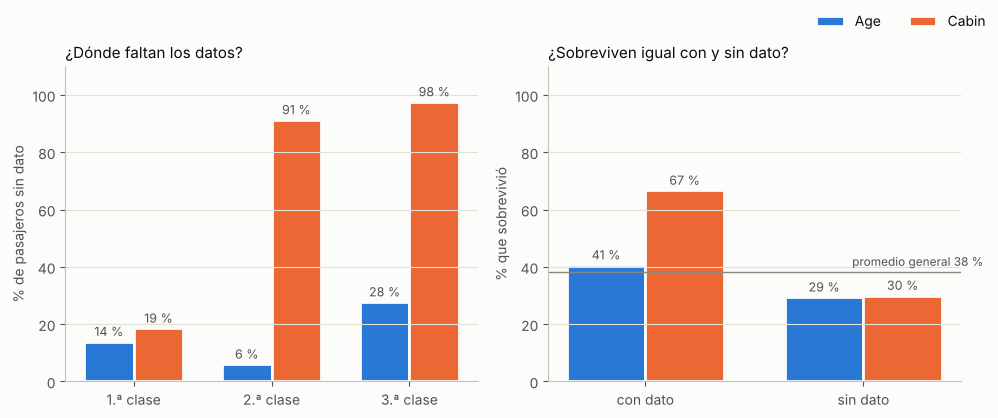

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))
ancho = 0.36
variables = [(-ancho / 2, "Age", AZUL), (ancho / 2, "Cabin", NARANJA)]

# Panel 1: % de pasajeros sin dato, por clase
x = np.arange(3)
for desplazamiento, col, color in variables:
    pct = titanic[col].isna().groupby(titanic["Pclass"]).mean() * 100
    barras = ax1.bar(x + desplazamiento, pct, ancho, color=color, label=col, edgecolor=SUPERFICIE, linewidth=2)
    ax1.bar_label(barras, fmt=lambda v: f"{v:.0f} %", padding=2, color=TINTA_2, fontsize=9)
ax1.set_xticks(x, ["1.ª clase", "2.ª clase", "3.ª clase"])
ax1.set_ylabel("% de pasajeros sin dato")
ax1.set_title("¿Dónde faltan los datos?", loc="left", fontsize=11)

# Panel 2: % que sobrevivió con y sin dato
x2 = np.arange(2)
for desplazamiento, col, color in variables:
    tasa = titanic.groupby(titanic[col].isna())["Survived"].mean() * 100   # índice: False = con dato
    barras = ax2.bar(x2 + desplazamiento, tasa, ancho, color=color, edgecolor=SUPERFICIE, linewidth=2)
    ax2.bar_label(barras, fmt=lambda v: f"{v:.0f} %", padding=2, color=TINTA_2, fontsize=9)
promedio = titanic["Survived"].mean() * 100
ax2.axhline(promedio, color="#898781", linewidth=1)
ax2.text(1.55, promedio + 2, f"promedio general {promedio:.0f} %", color=TINTA_2, fontsize=8.5, ha="right")
ax2.set_xticks(x2, ["con dato", "sin dato"])
ax2.set_ylabel("% que sobrevivió")
ax2.set_title("¿Sobreviven igual con y sin dato?", loc="left", fontsize=11)

for ax in (ax1, ax2):
    ax.set_ylim(0, 110)
    ax.grid(axis="x", visible=False)
fig.legend(*ax1.get_legend_handles_labels(), loc="upper right", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(FIGURAS_DIR / "b_titanic_faltantes.png", dpi=150)
plt.show()

**Interpretación:** los faltantes de `Cabin` y `Age` se concentran en 3.ª clase, y quienes no tienen esos datos sobrevivieron menos que el promedio (38 %). La ausencia es informativa: no conviene imputar a ciegas ni ignorarla.

### 1.3 Hallazgos principales — Titanic (producto parcial)

| # | Hallazgo | Evidencia | Implicación / acción | Rol |
|---|---|---|---|---|
| 1 | `Cabin` casi vacía | 687 nulos (77.1 %); faltan en el 97.6 % de 3.ª clase | No inventar camarotes: excluir la columna o usar solo `Cabin_missing`, documentando el riesgo de fuga | D |
| 2 | `Age` con faltantes no aleatorios | 177 nulos (19.9 %): 27.7 % en 3.ª vs 6.0 % en 2.ª; sobrevive 29 % sin edad vs 41 % con edad | Imputar con estadístico de train (comparar media vs mediana) y crear `Age_missing` | D |
| 3 | `Embarked` casi completa | 2 nulos (0.2 %), ambos con el boleto 113572 | Moda (`S`) o categoría "Desconocido"; impacto mínimo | D |
| 4 | `Fare` muy asimétrica y por boleto | Asimetría 4.79; media 32.2 vs mediana 14.5; 116 outliers IQR (13 %); máx. 512.33; 15 tarifas en 0 | Winsorizar (IQR o p1–p99, con límites de train) o usar log; recordar que es precio por boleto | D |
| 5 | Desbalance moderado | 549 vs 342 (61.6 % / 38.4 %); IR = 1.61 > 1.5 | Reportar precision, recall y F1, no solo accuracy | E |
| 6 | Identificadores sin valor predictivo | `PassengerId` y `Name` 100 % únicos; `Ticket` 681 valores | Excluirlos (ya en `excluir`); de `Name` solo extraer el título | A |
| 7 | Variables sensibles muy predictivas | Sobrevive 74.2 % de mujeres vs 18.9 % de hombres; 63.0 % en 1.ª vs 24.2 % en 3.ª | El modelo aprenderá reglas por sexo y clase: no extrapolarlo a decisiones actuales | Todos |
| 8 | Sin redundancia ni duplicados | Máx. \|r\| = 0.55 (`Pclass`–`Fare`); 0 duplicados exactos | No hace falta eliminar variables ni filas | — |

## 2. Credit Card Fraud

### 2.1 Comprensión del dominio

| Elemento | Descripción |
|---|---|
| **Fuente** | Kaggle, [*Credit Card Fraud Detection* (mlg-ulb/creditcardfraud)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). Datos de Worldline y del Machine Learning Group de la Université Libre de Bruxelles (ULB). Referencia: Dal Pozzolo, Caelen, Johnson y Bontempi (2015), *Calibrating Probability with Undersampling for Unbalanced Classification*, IEEE CIDM. |
| **Licencia** | Open Database License (ODbL 1.0), según Kaggle. |
| **Archivo** | `data/raw/creditcard.csv` (≈ 144 MB; **no se sube a GitHub**, cada integrante lo descarga y lo coloca en `data/raw/`). |
| **Dimensiones** | 284,807 filas × 31 columnas (se verifica abajo). |
| **Unidad de análisis** | Una transacción con tarjeta de crédito de titulares europeos, durante 2 días de septiembre de 2013. |
| **Variable objetivo** | `Class` (1 = fraude, 0 = legítima). |

In [19]:
fraud = cargar_datos("fraud")
assert fraud.shape == (284807, 31) and fraud["Class"].sum() == 492, (
    "creditcard.csv no coincide con la versión de Kaggle (284,807 filas, 31 columnas, 492 fraudes)")
print(f"Credit Card Fraud: {fraud.shape[0]:,} filas × {fraud.shape[1]} columnas")
fraud.head()

Credit Card Fraud: 284,807 filas × 31 columnas


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.000,-1.360,-0.073,2.536,1.378,-0.338,0.462,0.240,0.099,0.364,0.091,-0.552,-0.618,-0.991,-0.311,1.468,-0.470,0.208,0.026,0.404,0.251,-0.018,0.278,-0.110,0.067,0.129,-0.189,0.134,-0.021,149.620,0
1,0.000,1.192,0.266,0.166,0.448,0.060,-0.082,-0.079,0.085,-0.255,-0.167,1.613,1.065,0.489,-0.144,0.636,0.464,-0.115,-0.183,-0.146,-0.069,-0.226,-0.639,0.101,-0.340,0.167,0.126,-0.009,0.015,2.690,0
2,1.000,-1.358,-1.340,1.773,0.380,-0.503,1.800,0.791,0.248,-1.515,0.208,0.625,0.066,0.717,-0.166,2.346,-2.890,1.110,-0.121,-2.262,0.525,0.248,0.772,0.909,-0.689,-0.328,-0.139,-0.055,-0.060,378.660,0
3,1.000,-0.966,-0.185,1.793,-0.863,-0.010,1.247,0.238,0.377,-1.387,-0.055,-0.226,0.178,0.508,-0.288,-0.631,-1.060,-0.684,1.966,-1.233,-0.208,-0.108,0.005,-0.190,-1.176,0.647,-0.222,0.063,0.061,123.500,0
4,2.000,-1.158,0.878,1.549,0.403,-0.407,0.096,0.593,-0.271,0.818,0.753,-0.823,0.538,1.346,-1.120,0.175,-0.451,-0.237,-0.038,0.803,0.409,-0.009,0.798,-0.137,0.141,-0.206,0.502,0.219,0.215,69.990,0


**Diccionario de variables**

| Variable | dtype | Tipo semántico | Significado | Unidades / dominio |
|---|---|---|---|---|
| `Time` | float | numérica (temporal) | Segundos transcurridos desde la **primera transacción del archivo** | segundos; 0 – 172,792 (≈ 48 h) |
| `V1` … `V28` | float | numéricas (componentes PCA) | Componentes principales de atributos originales que no se publican por confidencialidad | sin unidades; centradas en 0 |
| `Amount` | float | numérica continua | Monto de la transacción | unidades monetarias (la fuente no indica la moneda); ≥ 0 |
| `Class` | int | **objetivo** (binaria) | ¿Es fraude? | 0 = legítima, 1 = fraude |

**Preguntas de dominio**

- **¿Qué representa cada fila?** Una transacción con tarjeta. No hay identificador de transacción, de tarjeta ni de cliente.
- **¿La variable objetivo estaría disponible en un escenario real?** No en el momento de la compra: el sistema debe decidir al **autorizar** la transacción, y el fraude se confirma días o semanas después (reclamo del cliente, contracargo, investigación). Además, un fraude no detectado queda etiquetado como 0, así que la clase positiva puede estar subestimada. `V1`–`V28` y `Amount` sí estarían disponibles al momento del pago, según la descripción de la fuente.
- **¿Existen identificadores o variables con fuga de información?** `Time` no es un identificador, pero mide segundos desde el inicio **de este archivo**: en producción ese valor no significa nada y además el archivo está ordenado por él. Conviene excluirlo o convertirlo a "hora del día". También hay **1,081 filas duplicadas** que con el split aleatorio pueden quedar en train y en test a la vez (paso 8). Como `V1`–`V28` son anónimas, **no podemos auditar** si alguna contiene información posterior a la transacción.
- **¿Qué decisiones podrían afectar de forma desigual a distintos grupos?** No hay variables demográficas visibles, pero las componentes PCA pueden codificar indirectamente ubicación, tipo de comercio o hábitos de consumo. Los errores tienen costos distintos: un **falso positivo** bloquea la tarjeta de un cliente legítimo y un **falso negativo** deja pasar un fraude. Como el fraude es más frecuente de madrugada (paso 6), quienes compran a esas horas (p. ej. personas que trabajan de noche) recibirían más bloqueos injustificados.

### 2.2 Data profiling

**Paso 4 · Separar columnas.** Todas las variables predictoras son numéricas; no hay categóricas. `Class` es la objetivo.

In [20]:
OBJ_F = "Class"
V_COLS = [f"V{i}" for i in range(1, 29)]
NUM_F = ["Time"] + V_COLS + ["Amount"]     # todas las predictoras son numéricas
CAT_F = []                                 # no hay categóricas: la clase es la única variable discreta

assert sorted(NUM_F + [OBJ_F]) == sorted(fraud.columns)
print(f"{len(NUM_F)} numéricas, {len(CAT_F)} categóricas, objetivo: {OBJ_F}")

30 numéricas, 0 categóricas, objetivo: Class


**Paso 5 · Tipo de dato, nulos y valores únicos (todas las columnas)**

In [21]:
res_fraud = resumen_columnas(fraud)
print("Nulos en todo el dataset:", int(res_fraud["nulos"].sum()))
res_fraud

Nulos en todo el dataset: 0


,dtype,nulos,%_nulos,unicos,%_unicos,%_valor_mas_frecuente
Time,float64,0,0.000,124592,43.746,0.013
V1,float64,0,0.000,275663,96.789,0.027
V2,float64,0,0.000,275663,96.789,0.027
V3,float64,0,0.000,275663,96.789,0.027
V4,float64,0,0.000,275663,96.789,0.027
V5,float64,0,0.000,275663,96.789,0.027
V6,float64,0,0.000,275663,96.789,0.027
V7,float64,0,0.000,275663,96.789,0.027
V8,float64,0,0.000,275663,96.789,0.027
V9,float64,0,0.000,275663,96.789,0.027


- **0 nulos en todo el dataset**, así que la imputación se estudia con Titanic.
- Todas las columnas son numéricas (30 `float64` y `Class` entera): no hace falta codificación one-hot.
- `V1`–`V28` tienen 275,663 valores distintos, no 284,807: hay filas que repiten exactamente el mismo vector (paso 8).

In [22]:
reglas_fraud = {
    "Class fuera de {0, 1}":          ("Class",  lambda s: ~s.isin([0, 1])),
    "Time < 0 o mayor a 2 días":      ("Time",   lambda s: (s < 0) | (s > 2 * 24 * 3600)),
    "Amount negativo":                ("Amount", lambda s: s < 0),
    "Amount con más de 2 decimales":  ("Amount", lambda s: (s * 100).round(6) % 1 != 0),
    # Valor válido, pero que conviene conocer
    "Amount = 0 (monto cero)":        ("Amount", lambda s: s == 0),
}
display(revisar_dominio(fraud, reglas_fraud))
print("Fraudes con Amount = 0:", int(fraud.loc[fraud["Amount"] == 0, OBJ_F].sum()))

,columna,n,%,ejemplos
regla,,,,
"Class fuera de {0, 1}",Class,0,0.000,[]
Time < 0 o mayor a 2 días,Time,0,0.000,[]
Amount negativo,Amount,0,0.000,[]
Amount con más de 2 decimales,Amount,0,0.000,[]
Amount = 0 (monto cero),Amount,1825,0.641,[0.0]


Fraudes con Amount = 0: 27


- No hay valores imposibles: ni montos negativos, ni `Time` fuera de los 2 días, ni clases distintas de 0/1. `Amount` nunca tiene más de 2 decimales, como corresponde a dinero.
- **1,825 transacciones tienen `Amount = 0`** (0.64 %), 27 de ellas fraudes. Son válidas (por ejemplo, verificaciones de tarjeta) y no deben tratarse como faltantes.

**Paso 6 · Variables numéricas.** Los límites IQR se calculan con todos los datos solo para describirlos; Rol D los recalcula con train.

In [23]:
perfil_num_fraud = perfil_numericas(fraud, NUM_F)
perfil_num_fraud

,min,max,media,mediana,desv_est,p1,p5,p25,p50,p75,p95,p99,asimetria,nivel_asimetria,curtosis,lim_inf_IQR,lim_sup_IQR,n_outliers_IQR,%_outliers_IQR
Time,0.000,"172,792.000","94,813.860","84,692.000","47,488.146","2,422.000","25,297.600","54,201.500","84,692.000","139,320.500","164,143.400","170,560.940",-0.036,baja,-1.294,"-73,477.000","266,999.000",0,0.000
V1,-56.408,2.455,0.000,0.018,1.959,-6.563,-2.899,-0.920,0.018,1.316,2.081,2.237,-3.281,alta,32.487,-4.274,4.670,7062,2.480
V2,-72.716,22.058,0.000,0.065,1.651,-4.960,-1.972,-0.599,0.065,0.804,1.809,3.802,-4.625,alta,95.773,-2.702,2.907,13526,4.749
V3,-48.326,9.383,-0.000,0.180,1.516,-3.978,-2.390,-0.890,0.180,1.027,2.063,2.728,-2.240,alta,26.620,-3.767,3.904,3363,1.181
V4,-5.683,16.875,0.000,-0.020,1.416,-3.123,-2.196,-0.849,-0.020,0.743,2.567,4.248,0.676,moderada,2.635,-3.237,3.131,11148,3.914
V5,-113.743,34.802,0.000,-0.054,1.380,-3.060,-1.702,-0.692,-0.054,0.612,2.099,3.425,-2.426,alta,206.905,-2.647,2.567,12295,4.317
V6,-26.161,73.302,0.000,-0.274,1.332,-2.124,-1.407,-0.768,-0.274,0.399,3.160,4.200,1.827,alta,42.642,-2.519,2.149,22965,8.063
V7,-43.557,120.589,-0.000,0.040,1.237,-3.013,-1.434,-0.554,0.040,0.570,1.408,2.696,2.554,alta,405.607,-2.241,2.257,8948,3.142
V8,-73.217,20.007,0.000,0.022,1.194,-4.034,-0.842,-0.209,0.022,0.327,1.050,2.076,-8.522,alta,220.587,-1.013,1.131,24134,8.474
V9,-13.434,15.595,-0.000,-0.051,1.099,-2.455,-1.758,-0.643,-0.051,0.597,1.781,2.987,0.555,moderada,3.731,-2.503,2.457,8283,2.908


- **`V1`–`V28`**: media ≈ 0 (las centró la PCA) y desviación estándar decreciente, de 1.96 (`V1`) a 0.33 (`V28`): es el orden de varianza de las componentes. **No** están estandarizadas a varianza 1.
- **Colas muy pesadas**: curtosis > 200 en `V5`, `V7`, `V8`, `V20`, `V21`, `V23`, `V27`, `V28` y `Amount`, con extremos muy lejos del resto (p. ej. el mínimo de `V5` es −113.7 y su percentil 1 es −3.06).
- **`Amount`**: media 88.35 vs mediana 22.00, asimetría **16.98**, máximo 25,691.16 con p99 = 1,017.97. La regla IQR marca como outlier al 11.2 % de las transacciones (todo lo que pasa de ≈ 184.5).
- **Escalas muy distintas**: `Time` llega a 172,792, `Amount` a 25,691 y las `V` casi nunca pasan de ±5. Hay que escalar antes de la regresión logística (ya lo hace `preprocesador_minimo()`).

In [24]:
# Amount según la clase
fraud.groupby(OBJ_F)["Amount"].describe(percentiles=[0.5, 0.95, 0.99]).rename(index={0: "legítima", 1: "fraude"})

,count,mean,std,min,50%,95%,99%,max
Class,,,,,,,,
legítima,"284,315.000",88.291,250.105,0.000,22.000,364.409,"1,016.966","25,691.160"
fraude,492.000,122.211,256.683,0.000,9.250,640.905,"1,357.428","2,125.870"


In [25]:
# Time: volumen y tasa de fraude por hora (contada desde el inicio de la captura)
hora = (fraud["Time"] // 3600 % 24).astype(int).rename("hora")
por_hora = fraud.groupby(hora)[OBJ_F].agg(transacciones="size", fraudes="sum")
por_hora["tasa_fraude_%"] = por_hora["fraudes"] / por_hora["transacciones"] * 100
por_hora.T

hora,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
transacciones,"7,695.000","4,220.000","3,328.000","3,492.000","2,209.000","2,990.000","4,101.000","7,243.000","10,276.000","15,838.000","16,598.000","16,856.000","15,420.000","15,365.000","16,570.000","16,461.000","16,453.000","16,166.000","17,039.000","15,649.000","16,756.000","17,703.000","15,441.000","10,938.000"
fraudes,6.000,10.000,57.000,17.000,23.000,11.000,9.000,23.000,9.000,16.000,8.000,53.000,17.000,17.000,23.000,26.000,22.000,29.000,33.000,19.000,18.000,16.000,9.000,21.000
tasa_fraude_%,0.078,0.237,1.713,0.487,1.041,0.368,0.219,0.318,0.088,0.101,0.048,0.314,0.110,0.111,0.139,0.158,0.134,0.179,0.194,0.121,0.107,0.090,0.058,0.192


- Los fraudes tienen **mediana menor** (9.25 vs 22.00) pero **media mayor** (122.21 vs 88.29): muchos son montos pequeños y unos pocos son grandes. El fraude más alto es de 2,125.87, muy por debajo del máximo general.
- **Hora del día:** el volumen cae entre las horas 1 y 6 (de noche, si la captura empezó cerca de la medianoche) y ahí la **tasa de fraude se dispara**: 1.71 % en la hora 2 y 1.04 % en la hora 4, contra ≈ 0.1 % durante el día. `Time` en bruto separa poco la clase (AUC 0.58, más abajo), pero la hora del día es una variable más interpretable.

**Paso 7 · Variables categóricas.** Fraud no tiene variables categóricas; solo se analiza la frecuencia de la clase objetivo.

In [26]:
display(frecuencias(fraud[OBJ_F]).rename(index={0: "0 = legítima", 1: "1 = fraude"}))
conteo_f = fraud[OBJ_F].value_counts()
print(f"IR = {conteo_f.max():,} / {conteo_f.min():,} = {conteo_f.max() / conteo_f.min():.1f}")
print(f"Accuracy de predecir siempre 'no fraude': {conteo_f.max() / conteo_f.sum():.2%}")

,n,%
Class,,
0 = legítima,284315,99.827
1 = fraude,492,0.173


IR = 284,315 / 492 = 577.9
Accuracy de predecir siempre 'no fraude': 99.83%


- **492 fraudes de 284,807** transacciones (0.173 %). IR = 284,315 / 492 = **577.9**, muy por encima de 1.5: **desbalance extremo**.
- Un modelo que dijera siempre "no fraude" tendría **99.83 % de accuracy** y 0 % de recall. Aquí accuracy no sirve; hay que mirar precision, recall, F1 y PR-AUC (Rol E).

**Paso 8 · Duplicados, columnas casi constantes, identificadores, correlaciones y posibles fugas**

In [27]:
dup = fraud.duplicated()
print(f"Filas duplicadas exactas: {dup.sum():,} ({dup.mean():.2%}), de ellas fraudes: {fraud.loc[dup, OBJ_F].sum()}")
print(f"Sin duplicados quedarían {(~dup).sum():,} filas y {fraud.loc[~dup, OBJ_F].sum()} fraudes")

# ¿Alguna copia tiene una etiqueta distinta? (mismos atributos, distinta clase)
copias = fraud[fraud.duplicated(subset=NUM_F, keep=False)]
print("Grupos de copias con etiqueta contradictoria:", int((copias.groupby(NUM_F)[OBJ_F].nunique() > 1).sum()))

# Con el split del equipo, ¿cuántas filas de test tienen una copia exacta en train?
X_tr, X_te, y_tr, y_te = dividir(fraud, "fraud")
en_train = pd.util.hash_pandas_object(X_te, index=False).isin(
    pd.util.hash_pandas_object(X_tr, index=False)).to_numpy()
print(f"Filas de test con copia exacta en train: {en_train.sum()} "
      f"(fraudes: {y_te[en_train].sum()} de {y_te.sum()} fraudes de test)")

# Mismo vector V1–V28 y mismo Amount que otra fila, pero en otro momento (Time distinto)
mismo_vector = fraud.duplicated(subset=V_COLS + ["Amount"]) & ~dup
print(f"Filas que repiten V1–V28 y Amount de otra fila con distinto Time: {mismo_vector.sum():,}")

Filas duplicadas exactas: 1,081 (0.38%), de ellas fraudes: 19
Sin duplicados quedarían 283,726 filas y 473 fraudes


Grupos de copias con etiqueta contradictoria: 0


Filas de test con copia exacta en train: 456 (fraudes: 7 de 148 fraudes de test)


Filas que repiten V1–V28 y Amount de otra fila con distinto Time: 8,063


- **1,081 filas duplicadas exactas** (0.38 %), 19 de ellas fraudes; ningún grupo de copias tiene etiquetas contradictorias. Sin duplicados quedan 283,726 filas y 473 fraudes.
- **Consecuencia para la evaluación:** con el split del equipo (`dividir()`, semilla 42), **456 filas de test tienen una copia idéntica en train**, incluidos 7 de los 148 fraudes de test (4.7 %). El modelo "ya vio" esas transacciones, lo que infla un poco las métricas, sobre todo el recall. **Recomendación para Rol A:** eliminar los duplicados exactos **antes** de dividir.
- Además, 8,063 filas repiten el vector `V1`–`V28` y el monto de otra fila en otro momento (¿cargos recurrentes de la misma tarjeta en el mismo comercio?). Sin un ID de tarjeta no es posible separar train y test por cliente, así que la evaluación puede ser algo optimista.

In [28]:
print("Columnas casi constantes (> 95 % un solo valor):", columnas_casi_constantes(fraud).round(4).to_dict())
ids_f = posibles_identificadores(fraud)
print("Posibles identificadores:", list(ids_f.index) or "ninguno")
print("¿Time está ordenada de forma creciente?", fraud["Time"].is_monotonic_increasing)
print(f"Time va de {fraud['Time'].min():,.0f} a {fraud['Time'].max():,.0f} s (≈ {fraud['Time'].max() / 3600:.0f} horas)")

Columnas casi constantes (> 95 % un solo valor): {'Class': 0.9983}
Posibles identificadores: ninguno
¿Time está ordenada de forma creciente? True
Time va de 0 a 172,792 s (≈ 48 horas)


- Ninguna variable predictora es casi constante: solo `Class` supera el 95 %, que es otra forma de ver el desbalance.
- No hay identificadores explícitos (ni de transacción, ni de tarjeta, ni de cliente).
- `Time` está **ordenada de forma creciente**: el archivo es cronológico y `Time` funciona como un índice temporal relativo al inicio de la captura (0 a 48 h), por lo que no generaliza a datos nuevos.

In [29]:
altas_f, top_f = pares_correlacion_alta(fraud, NUM_F)
max_r_V = fraud[V_COLS].corr().where(~np.eye(len(V_COLS), dtype=bool)).abs().max().max()
print("Pares con |r| > 0.8:", len(altas_f))
print(f"Máxima |r| entre dos componentes V: {max_r_V:.1e}")
top_f

Pares con |r| > 0.8: 0
Máxima |r| entre dos componentes V: 2.3e-14


,var_1,var_2,r,|r|
0,V2,Amount,-0.531,0.531
1,Time,V3,-0.420,0.420
2,V7,Amount,0.397,0.397
3,V5,Amount,-0.386,0.386
4,V20,Amount,0.339,0.339


- **Ningún par supera |r| = 0.8.** Las `V` no están correlacionadas entre sí (|r| ≈ 0, una propiedad de la PCA), así que no hay multicolinealidad que justifique eliminar variables.
- Las correlaciones moderadas aparecen solo con las variables no transformadas: `V2`–`Amount` (−0.53), `V3`–`Time` (−0.42), `V7`–`Amount` (0.40) y `V5`–`Amount` (−0.39).

In [30]:
asoc_f = asociacion_con_objetivo(fraud, OBJ_F, numericas=NUM_F)
display(asoc_f.head(8))
asoc_f[asoc_f["variable"].isin(["Time", "Amount"])]

,variable,tipo,medida,valor,direccion,revisar_fuga
0,V14,numérica,AUC univariada,0.949,−,False
1,V4,numérica,AUC univariada,0.938,+,False
2,V12,numérica,AUC univariada,0.937,−,False
3,V11,numérica,AUC univariada,0.918,+,False
4,V10,numérica,AUC univariada,0.914,−,False
5,V3,numérica,AUC univariada,0.912,−,False
6,V2,numérica,AUC univariada,0.855,+,False
7,V16,numérica,AUC univariada,0.847,−,False


,variable,tipo,medida,valor,direccion,revisar_fuga
21,Time,numérica,AUC univariada,0.581,−,False
23,Amount,numérica,AUC univariada,0.558,−,False


- Ninguna variable llega por sí sola a 0.95 de AUC, aunque varias se acercan: `V14` (0.949), `V4` (0.938), `V12` (0.937), `V11` (0.918) y `V10` (0.914). Son muy predictivas, pero según la fuente describen la transacción al momento del pago: son **señal legítima, no fuga** (con la salvedad de que no podemos auditarlas).
- `Time` (0.58) y `Amount` (0.56) aportan poco por sí solas.

**¿Los outliers son errores o señal?** Para cada variable se compara qué porcentaje de fraudes y de transacciones legítimas cae fuera de los límites IQR.

In [31]:
es_fraude = fraud[OBJ_F] == 1
filas, alguna_V = {}, pd.Series(False, index=fraud.index)
for c in V_COLS + ["Amount"]:
    lim_inf, lim_sup = limites_iqr(fraud[c])
    fuera = (fraud[c] < lim_inf) | (fraud[c] > lim_sup)
    if c in V_COLS:
        alguna_V |= fuera
    filas[c] = {"%_fraudes_outlier": fuera[es_fraude].mean() * 100,
                "%_legitimas_outlier": fuera[~es_fraude].mean() * 100,
                "tasa_fraude_en_outliers_%": es_fraude[fuera].mean() * 100,
                "tasa_fraude_en_el_resto_%": es_fraude[~fuera].mean() * 100}
outliers_vs_clase = (pd.DataFrame.from_dict(filas, orient="index")
                       .sort_values("%_fraudes_outlier", ascending=False))

print(f"Transacciones con al menos un outlier en alguna V: {alguna_V.mean():.1%} del total "
      f"y {alguna_V[es_fraude].mean():.1%} de los fraudes")
p1, p99 = fraud["V14"].quantile([0.01, 0.99])
recorte = (fraud["V14"] < p1) | (fraud["V14"] > p99)
print(f"Winsorizar V14 en p1–p99 cambiaría el valor de {recorte[es_fraude].mean():.1%} de los fraudes "
      f"y de {recorte[~es_fraude].mean():.1%} de las legítimas")
outliers_vs_clase.head(10)

Transacciones con al menos un outlier en alguna V: 45.2% del total y 97.0% de los fraudes
Winsorizar V14 en p1–p99 cambiaría el valor de 83.7% de los fraudes y de 1.9% de las legítimas


,%_fraudes_outlier,%_legitimas_outlier,tasa_fraude_en_outliers_%,tasa_fraude_en_el_resto_%
V14,87.398,4.825,3.039,0.023
V12,83.130,5.254,2.665,0.031
V10,81.098,3.200,4.202,0.034
V17,80.691,2.470,5.350,0.034
V16,71.341,2.755,4.289,0.051
V27,69.919,13.654,0.878,0.060
V4,64.634,3.809,2.853,0.064
V3,63.415,1.073,9.277,0.064
V7,61.179,3.041,3.364,0.069
V11,59.756,0.171,37.692,0.070


**Pregunta de la figura:** ¿los valores extremos de Fraud son errores que hay que recortar o son la señal de fraude?

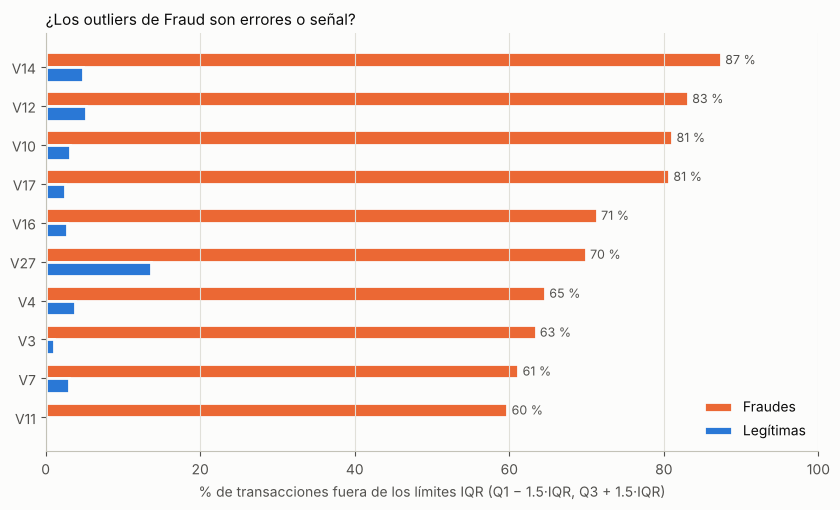

In [32]:
top = outliers_vs_clase.head(10).iloc[::-1]          # las 10 variables con más fraudes fuera de rango
y, alto = np.arange(len(top)), 0.38
fig, ax = plt.subplots(figsize=(8.5, 5.2))
b_fraude = ax.barh(y + alto / 2, top["%_fraudes_outlier"], alto, color=NARANJA, label="Fraudes",
                   edgecolor=SUPERFICIE, linewidth=2)
ax.barh(y - alto / 2, top["%_legitimas_outlier"], alto, color=AZUL, label="Legítimas",
        edgecolor=SUPERFICIE, linewidth=2)
ax.bar_label(b_fraude, fmt=lambda v: f"{v:.0f} %", padding=3, color=TINTA_2, fontsize=9)
ax.set_yticks(y, top.index)
ax.set_xlim(0, 100)
ax.set_xlabel("% de transacciones fuera de los límites IQR (Q1 − 1.5·IQR, Q3 + 1.5·IQR)")
ax.set_title("¿Los outliers de Fraud son errores o señal?", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURAS_DIR / "b_fraud_outliers_vs_clase.png", dpi=150)
plt.show()

**Interpretación:** son señal. El 87 % de los fraudes son outliers IQR en `V14` (frente al 4.8 % de las legítimas), y entre esos outliers la tasa de fraude es 3.0 % contra 0.02 % en el resto, unas 130 veces más. El 97 % de los fraudes tiene al menos un outlier en alguna `V`. Winsorizar `V14` en p1–p99 cambiaría el valor del 84 % de los fraudes. **Recomendación para Rol D:** en Fraud, winsorizar solo `Amount` y no recortar `V1`–`V28` (o hacerlo solo como experimento, midiendo cuánto cae el recall).

### 2.3 Hallazgos principales — Credit Card Fraud (producto parcial)

| # | Hallazgo | Evidencia | Implicación / acción | Rol |
|---|---|---|---|---|
| 1 | Desbalance extremo | 492 fraudes de 284,807 (0.173 %); IR = 577.9 | Accuracy engaña (99.83 % diciendo siempre "no fraude"): usar precision, recall, F1 y PR-AUC; balancear solo train | E |
| 2 | Los outliers son la señal de fraude | 87 % de los fraudes son outliers IQR en `V14` (vs 4.8 % de las legítimas); 97 % tiene al menos uno en alguna `V` | No winsorizar `V1`–`V28`; si acaso, solo `Amount`, midiendo el efecto en el recall | D |
| 3 | `Amount` muy asimétrica | Asimetría 16.98; media 88.35 vs mediana 22.00; máx. 25,691.16; p99 = 1,017.97; 11.2 % outliers IQR | Winsorizar con p1–p99 (límites de train) o usar log1p; IQR (lím. sup. ≈ 184.5) recorta demasiado | D |
| 4 | Duplicados que contaminan el split | 1,081 filas duplicadas (0.38 %; 19 fraudes); 456 filas de test tienen copia en train (7 fraudes) | Eliminar duplicados antes de dividir para no inflar las métricas | A |
| 5 | `Time` no generaliza | Segundos desde la primera transacción (0–48 h); archivo ordenado; fraude 1.71 % en la hora 2 vs ≈ 0.1 % de día | Excluir `Time` o convertirlo a hora del día; el split aleatorio no simula producción | A |
| 6 | Sin nulos ni categóricas | 0 nulos; 31 columnas numéricas | La imputación se estudia con Titanic; no hay one-hot | D |
| 7 | Variables anónimas (PCA) en escalas distintas | `V1`–`V28` con media 0 y \|r\| ≈ 0 entre sí; `Time` hasta 172,792 y `Amount` hasta 25,691 | Escalar antes del modelo; no es posible interpretar ni auditar sesgos o fugas en las `V` | Todos |
| 8 | Montos en cero | 1,825 transacciones (0.64 %), 27 fraudes | Son válidos (p. ej. verificaciones de tarjeta): no tratarlos como faltantes | D |

## 3. Entregas para los demás roles

### Para Rol D: columnas a imputar y winsorizar

La tabla junta los números clave de cada columna con una sugerencia de tratamiento. Los límites IQR y los percentiles se calcularon con **todos** los datos: Rol D debe recalcularlos **solo con `X_train`**.

In [33]:
recomendaciones_d = pd.DataFrame([
    ("titanic", "Age", "Imputar",
     "Comparar media vs mediana (ajustadas solo con train) y agregar Age_missing: la ausencia es informativa. "
     "Opcional: KNN o mediana por título (Master ≈ 3.5 años)."),
    ("titanic", "Embarked", "Imputar",
     "Moda ('S') vs categoría 'Desconocido'. Solo 2 filas: impacto mínimo."),
    ("titanic", "Cabin", "No imputar el valor",
     "77 % de nulos: no hay base para inventar camarotes. Excluir (ya está en excluir) o usar solo Cabin_missing, "
     "documentando el riesgo de fuga parcial."),
    ("titanic", "Fare", "Winsorizar",
     "Asimetría alta y 13 % de outliers IQR. Comparar IQR vs p1–p99 con límites de train. Fare = 0 es válido "
     "(boletos de cortesía)."),
    ("titanic", "Parch", "No winsorizar con IQR",
     "Conteo discreto con IQR = 0: la regla marcaría como outlier a todo el que viaja con padres o hijos."),
    ("fraud", "Amount", "Winsorizar",
     "Asimetría ≈ 17. p1–p99 es razonable; IQR recorta al 11 % de las transacciones (lím. sup. ≈ 184.5). "
     "Alternativa: log1p."),
    ("fraud", "V14", "No winsorizar (aplica a V1–V28)",
     "Los outliers son la señal de fraude: el 87 % de los fraudes son outliers IQR en V14. Recortarlos borra información."),
], columns=["dataset", "columna", "tratamiento", "justificacion"])

estadisticas = pd.concat({"titanic": res_titanic.join(perfil_num_titanic),
                          "fraud": res_fraud.join(perfil_num_fraud)},
                         names=["dataset", "columna"]).reset_index()
para_rol_d = recomendaciones_d.merge(
    estadisticas[["dataset", "columna", "nulos", "%_nulos", "asimetria", "%_outliers_IQR",
                  "lim_inf_IQR", "lim_sup_IQR", "p1", "p99"]],
    on=["dataset", "columna"], how="left")
with pd.option_context("display.max_colwidth", None):
    display(para_rol_d)

,dataset,columna,tratamiento,justificacion,nulos,%_nulos,asimetria,%_outliers_IQR,lim_inf_IQR,lim_sup_IQR,p1,p99
0,titanic,Age,Imputar,Comparar media vs mediana (ajustadas solo con train) y agregar Age_missing: la ausencia es informativa. Opcional: KNN o mediana por título (Master ≈ 3.5 años).,177,19.865,0.389,1.541,-6.688,64.812,1.000,65.870
1,titanic,Embarked,Imputar,Moda ('S') vs categoría 'Desconocido'. Solo 2 filas: impacto mínimo.,2,0.224,NaN,NaN,NaN,NaN,NaN,NaN
2,titanic,Cabin,No imputar el valor,"77 % de nulos: no hay base para inventar camarotes. Excluir (ya está en excluir) o usar solo Cabin_missing, documentando el riesgo de fuga parcial.",687,77.104,NaN,NaN,NaN,NaN,NaN,NaN
3,titanic,Fare,Winsorizar,Asimetría alta y 13 % de outliers IQR. Comparar IQR vs p1–p99 con límites de train. Fare = 0 es válido (boletos de cortesía).,0,0.000,4.787,13.019,-26.724,65.634,0.000,249.006
4,titanic,Parch,No winsorizar con IQR,Conteo discreto con IQR = 0: la regla marcaría como outlier a todo el que viaja con padres o hijos.,0,0.000,2.749,23.906,0.000,0.000,0.000,4.000
5,fraud,Amount,Winsorizar,Asimetría ≈ 17. p1–p99 es razonable; IQR recorta al 11 % de las transacciones (lím. sup. ≈ 184.5). Alternativa: log1p.,0,0.000,16.978,11.202,-101.748,184.512,0.120,"1,017.970"
6,fraud,V14,No winsorizar (aplica a V1–V28),Los outliers son la señal de fraude: el 87 % de los fraudes son outliers IQR en V14. Recortarlos borra información.,0,0.000,-1.995,4.968,-1.804,1.871,-2.800,2.150


### Para Rol C: hallazgos que conviene graficar

| Dataset | Pregunta | Gráfica sugerida | Dato clave |
|---|---|---|---|
| Titanic | ¿El sexo y la clase influyen juntos en la supervivencia? | Barras agrupadas: tasa de supervivencia por `Sex` y `Pclass` | Mujeres de 1.ª: 97 %; hombres de 3.ª: 14 % |
| Titanic | ¿La edad influye en la supervivencia? | Histograma o densidad de `Age` por `Survived` | Menores de 16 años: sobrevive el 59 % |
| Titanic | ¿Qué tan asimétrica es la tarifa y cómo cambia por clase? | Boxplot de `Fare` por `Pclass` (escala log) | Asimetría 4.79; máx. 512.33 |
| Titanic | ¿Dónde faltan los datos? | `figuras/b_titanic_faltantes.png` (ya hecha) | `Cabin` falta en el 97.6 % de 3.ª clase |
| Fraud | ¿Qué tan raro es el fraude? | Barras de `Class` (escala log) | 492 de 284,807 (0.173 %) |
| Fraud | ¿Los fraudes tienen montos distintos? | Histograma de `Amount` (escala log) por clase | Mediana 9.25 (fraude) vs 22.00 (legítima) |
| Fraud | ¿Hay horas con más fraude? | Línea: tasa de fraude por hora del día | 1.71 % en la hora 2 vs ≈ 0.1 % de día |
| Fraud | ¿Qué variables separan mejor la clase? | Boxplots de `V14`, `V12`, `V10` y `V17` por clase | AUC univariada de `V14`: 0.949 |
| Fraud | ¿Hay redundancia entre variables? | Heatmap de la matriz de correlación | Las `V` no se correlacionan entre sí; máx. \|r\| = 0.53 (`V2`–`Amount`) |
| Fraud | ¿Los outliers son errores o señal? | `figuras/b_fraud_outliers_vs_clase.png` (ya hecha) | 87 % de los fraudes son outliers en `V14` |

### Para Rol A (integrador) y Rol E

- **Fraud, duplicados:** eliminar las 1,081 filas duplicadas antes de `dividir()`; hoy 456 filas de test tienen copia exacta en train.
- **Fraud, `Time`:** decidir en equipo si se excluye (agregarlo a `DATASETS["fraud"]["excluir"]`) o se reemplaza por la hora del día. Hoy la línea base lo usa tal cual.
- **Titanic, `Pclass`:** `columnas_por_tipo()` la trata como numérica (se escala). Es aceptable para la regresión logística porque es ordinal; la alternativa es one-hot.
- **Rol E, desbalance:** Titanic IR = 1.61 (moderado; accuracy de la clase mayoritaria 61.6 %). Fraud IR = 577.9 (extremo; accuracy de la clase mayoritaria 99.83 %).

## 4. Exportar tablas

Se guardan en `resultados/` para que los demás roles las usen sin volver a correr este notebook. Las figuras ya quedaron en `figuras/`.

Se usa la codificación `utf-8-sig` (UTF-8 con una marca inicial llamada BOM) para que Excel muestre bien los acentos; pandas las lee igual con `pd.read_csv()`.

In [34]:
tablas = {
    "profiling_columnas.csv": pd.concat({"titanic": res_titanic, "fraud": res_fraud},
                                        names=["dataset", "columna"]),
    "profiling_numericas.csv": pd.concat({"titanic": perfil_num_titanic, "fraud": perfil_num_fraud},
                                         names=["dataset", "columna"]),
    "profiling_categoricas_titanic.csv": perfil_cat_titanic.rename_axis("columna"),
    "profiling_fraud_outliers_vs_clase.csv": outliers_vs_clase.rename_axis("columna"),
    "rol_b_para_rol_d.csv": para_rol_d.set_index(["dataset", "columna"]),
}
RESULTADOS_DIR.mkdir(exist_ok=True)
for nombre, tabla in tablas.items():
    tabla.to_csv(RESULTADOS_DIR / nombre, encoding="utf-8-sig")   # utf-8-sig: Excel reconoce los acentos
list(tablas)

['profiling_columnas.csv',
 'profiling_numericas.csv',
 'profiling_categoricas_titanic.csv',
 'profiling_fraud_outliers_vs_clase.csv',
 'rol_b_para_rol_d.csv']

---

**Resumen de Rol B.** Titanic necesita sobre todo **imputación** (`Age` y `Embarked`; `Cabin` solo como indicador) y **winsorización de `Fare`**, y su desbalance es moderado. Fraud no tiene nulos, pero tiene **desbalance extremo**, **duplicados** que contaminan el split, una variable `Time` que no generaliza y **outliers que son la señal del fraude**, por lo que `V1`–`V28` no deben recortarse.